In [ ]:
! pip install torch

In [20]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, f1_score, roc_auc_score

Chargement et préparation des données

In [ ]:
data = pd.read_csv("data/data_preprocessed.csv")
data_processed = data.sort_values(by='time_of_day')

In [23]:
train_size = int(len(data_processed) * 0.7)
val_size   = int(len(data_processed) * 0.15)

train_data = data_processed.iloc[:train_size]
val_data   = data_processed.iloc[train_size:train_size + val_size]
test_data  = data_processed.iloc[train_size + val_size:]

X_train = train_data.drop(columns=['normality'])
y_train = train_data['normality']

X_val = val_data.drop(columns=['normality'])
y_val = val_data['normality']

X_test = test_data.drop(columns=['normality'])
y_test = test_data['normality']


Entraînement en One-Class Learning

On conserve uniquement les données normales (0) pour l’apprentissage.

In [24]:
X_train_normal = X_train[y_train == 0]

Normalisation des données

In [26]:
scaler = StandardScaler()

X_train_normal_scaled = scaler.fit_transform(X_train_normal)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

X_train_tensor = torch.tensor(X_train_normal_scaled, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test_scaled, dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(X_train_tensor),
    batch_size=256,
    shuffle=True
)


Définition de l’Autoencoder (DNN)

In [27]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16)
        )

        self.decoder = nn.Sequential(
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat


Initialisation du modèle



In [28]:
input_dim = X_train_tensor.shape[1]

model = Autoencoder(input_dim)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


Entraînement de l’Autoencoder

In [29]:
num_epochs = 50

for epoch in range(num_epochs):
    model.train()
    train_loss = 0

    for (x,) in train_loader:
        optimizer.zero_grad()
        x_hat = model(x)
        loss = criterion(x_hat, x)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * x.size(0)

    train_loss /= len(train_loader.dataset)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {train_loss:.6f}")

Epoch [10/50], Loss: 0.051011
Epoch [20/50], Loss: 0.037364
Epoch [30/50], Loss: 0.027110
Epoch [40/50], Loss: 0.018595
Epoch [50/50], Loss: 0.014552


Calcul des erreurs de reconstruction

In [30]:
model.eval()
with torch.no_grad():
    X_val_pred  = model(X_val_tensor)
    X_test_pred = model(X_test_tensor)

val_errors = torch.mean((X_val_tensor - X_val_pred) ** 2, dim=1).numpy()
test_errors = torch.mean((X_test_tensor - X_test_pred) ** 2, dim=1).numpy()

Recherche du seuil optimal (F1)

In [31]:
percentiles = np.arange(95, 100, 0.1)

best_f1 = 0
best_thresh = None

for p in percentiles:
    thresh = np.percentile(val_errors, p)
    y_val_pred = (val_errors >= thresh).astype(int)
    f1 = f1_score(y_val, y_val_pred)

    if f1 > best_f1:
        best_f1 = f1
        best_thresh = thresh

print(f"Seuil optimal : {best_thresh:.6f} | F1 = {best_f1:.4f}")

Seuil optimal : 0.125966 | F1 = 0.8993


Évaluation finale (Validation & Test)

In [32]:
y_val_pred  = (val_errors >= best_thresh).astype(int)
y_test_pred = (test_errors >= best_thresh).astype(int)

print("Validation :")
print(classification_report(y_val, y_val_pred))
print("ROC-AUC Validation :", roc_auc_score(y_val, val_errors))

print("\nTest :")
print(classification_report(y_test, y_test_pred))
print("ROC-AUC Test :", roc_auc_score(y_test, test_errors))

Validation :
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     51124
           1       0.87      0.93      0.90      2568

    accuracy                           0.99     53692
   macro avg       0.93      0.96      0.95     53692
weighted avg       0.99      0.99      0.99     53692

ROC-AUC Validation : 0.9943965115907788

Test :
              precision    recall  f1-score   support

           0       1.00      0.94      0.97     53193
           1       0.13      1.00      0.24       501

    accuracy                           0.94     53694
   macro avg       0.57      0.97      0.60     53694
weighted avg       0.99      0.94      0.96     53694

ROC-AUC Test : 0.9978644782136891


Matrices de confusion



Matrice de confusion — Validation

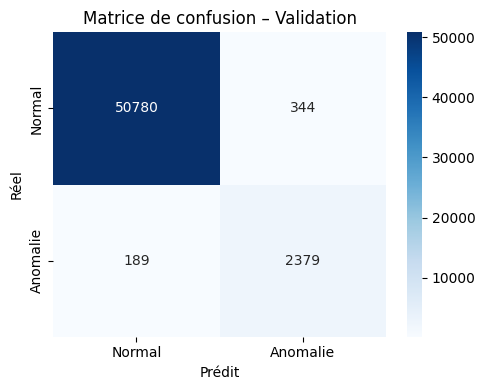

In [33]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


cm_val = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm_val, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Anomalie"],
            yticklabels=["Normal", "Anomalie"])
plt.title("Matrice de confusion – Validation")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.tight_layout()
plt.show()


Matrice de confusion — Test

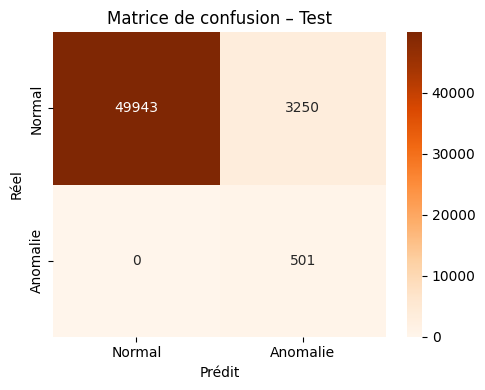

In [34]:
cm_test = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Oranges",
            xticklabels=["Normal", "Anomalie"],
            yticklabels=["Normal", "Anomalie"])
plt.title("Matrice de confusion – Test")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.tight_layout()
plt.show()

Courbes ROC (Validation & Test)

In [35]:
from sklearn.metrics import roc_curve


Courbe ROC — Validation

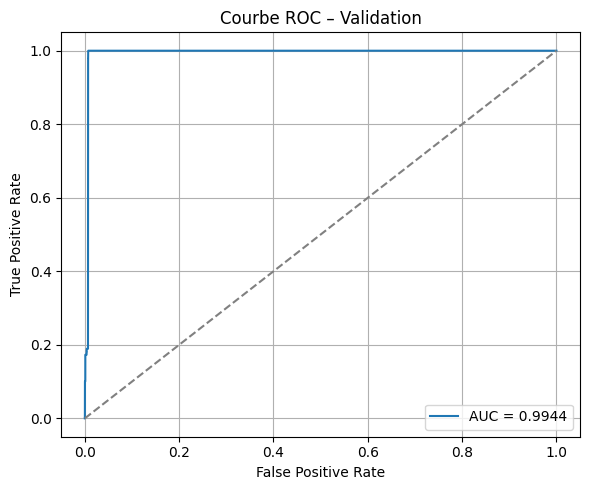

In [36]:
fpr_val, tpr_val, _ = roc_curve(y_val, val_errors)
auc_val = roc_auc_score(y_val, val_errors)

plt.figure(figsize=(6,5))
plt.plot(fpr_val, tpr_val, label=f"AUC = {auc_val:.4f}")
plt.plot([0,1], [0,1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Courbe ROC – Validation")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Courbe ROC — Test

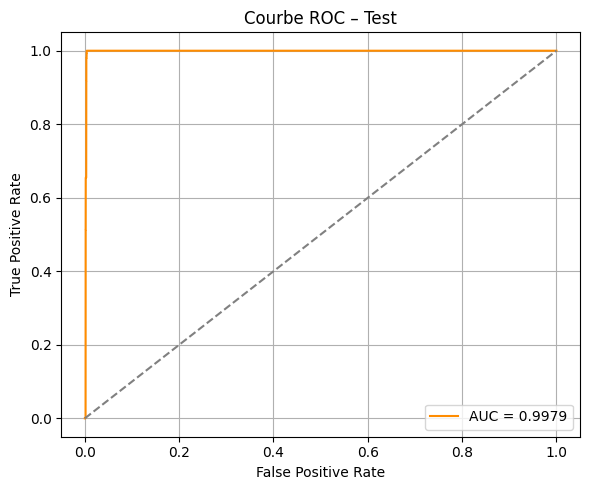

In [37]:
fpr_test, tpr_test, _ = roc_curve(y_test, test_errors)
auc_test = roc_auc_score(y_test, test_errors)

plt.figure(figsize=(6,5))
plt.plot(fpr_test, tpr_test, label=f"AUC = {auc_test:.4f}", color="darkorange")
plt.plot([0,1], [0,1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Courbe ROC – Test")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Distribution des erreurs de reconstruction

Validation

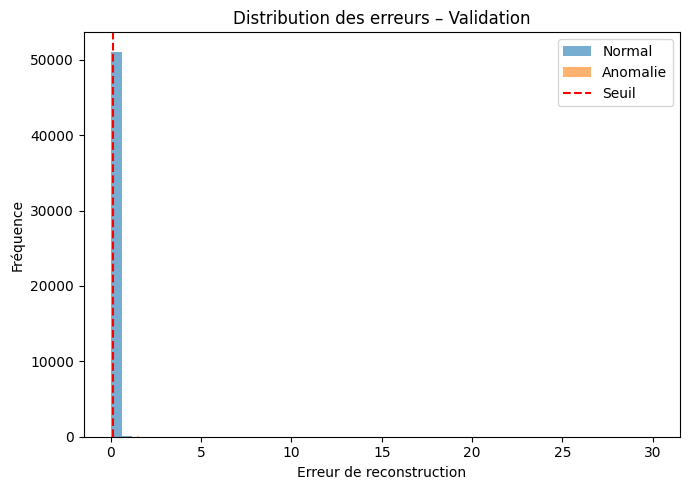

In [38]:
plt.figure(figsize=(7,5))
plt.hist(val_errors[y_val == 0], bins=50, alpha=0.6, label="Normal")
plt.hist(val_errors[y_val == 1], bins=50, alpha=0.6, label="Anomalie")
plt.axvline(best_thresh, color="red", linestyle="--", label="Seuil")
plt.title("Distribution des erreurs – Validation")
plt.xlabel("Erreur de reconstruction")
plt.ylabel("Fréquence")
plt.legend()
plt.tight_layout()
plt.show()

Test

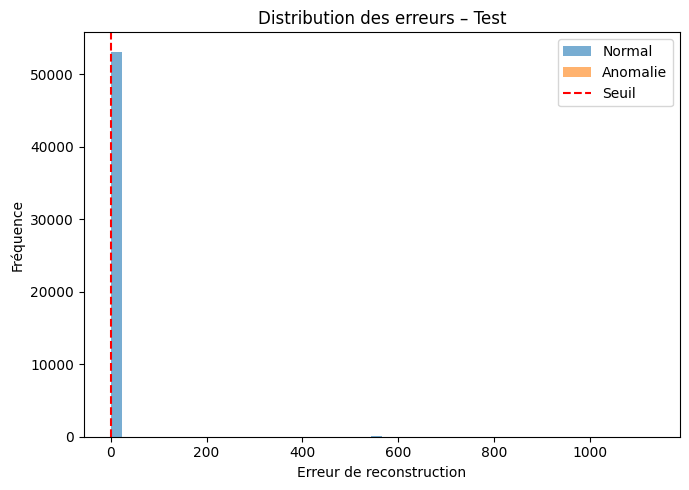

In [39]:
plt.figure(figsize=(7,5))
plt.hist(test_errors[y_test == 0], bins=50, alpha=0.6, label="Normal")
plt.hist(test_errors[y_test == 1], bins=50, alpha=0.6, label="Anomalie")
plt.axvline(best_thresh, color="red", linestyle="--", label="Seuil")
plt.title("Distribution des erreurs – Test")
plt.xlabel("Erreur de reconstruction")
plt.ylabel("Fréquence")
plt.legend()
plt.tight_layout()
plt.show()